# 22｜先看真实案例和环境

这套课面向第一次使用 Python 图像处理的人。先观察照片，再运行一个小算法，最后检查算法在哪些条件下失效。每本都能单独从上到下执行，建议先读本课。

**操作：**在 JupyterLab 打开笔记本，选中代码格按 `Shift + Enter`。第一次从第一个代码格开始。变量保存当前笔记本的图像，下一格会继续使用；重启内核后应重新逐格运行。

学完本课应能区分：真实照片、原始标注、算法输出、人工真值、派生图。我们使用三个任务：焊缝外观、金属表面缺陷、真实零件数量。没有把它们伪装成刀片电池的七格数据。

In [1]:
from pathlib import Path
import sys, json
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "course_utils.py").is_file())
INDUSTRIAL_ROOT = ROOT / "courses" / "industrial-vision-lab"
if str(INDUSTRIAL_ROOT) not in sys.path:
    sys.path.insert(0, str(INDUSTRIAL_ROOT))
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, HTML
import lab_utils as lab
print("OpenCV", cv2.__version__, "| NumPy", np.__version__)

OpenCV 4.12.0 | NumPy 2.2.6


## 1. 确认数据没有被换掉

读图之前核对 SHA256。它能发现文件变化，但不能证明标注正确或不同照片来自不同零件。下载器只取少量公开样本，完整工业档案保存在被忽略的缓存中。

In [2]:
rows = lab.manifest()["files"]
image_rows = [row for row in rows if row["kind"] == "image"]
for row in image_rows:
    image = lab.load_case(row["id"])
    print(row["id"], image.shape, row["license"], row["sha256"][:16])
assert len({row["dataset"] for row in image_rows}) >= 3
assert not lab.manifest()["private_images_included"]

parts_separated (239, 638, 3) CC-BY-SA-3.0 09d52fde302518f5
parts_occluded (1500, 2000, 3) CC-BY-SA-4.0 efb1cb24f71a22a1
weld_good (640, 640, 3) CC0-1.0 a57d4e8615c3c87e
weld_crack (640, 640, 3) CC0-1.0 4ae59bd790ea6ae4
weld_other (640, 640, 3) CC0-1.0 dca734f3287f823a
kolektor_normal_0 (1263, 500, 3) CC-BY-NC-SA-4.0 c56bc31a04a9479a
kolektor_normal_1 (1261, 500, 3) CC-BY-NC-SA-4.0 7790fd2f4c2c215b
kolektor_normal_2 (1254, 500, 3) CC-BY-NC-SA-4.0 2123d9b79fab20bc
kolektor_defect_0 (1270, 500, 3) CC-BY-NC-SA-4.0 eab8b6596d1d0d70
kolektor_defect_1 (1260, 500, 3) CC-BY-NC-SA-4.0 506f97b9bdc6c689
kolektor_defect_2 (1260, 500, 3) CC-BY-NC-SA-4.0 cd5b7c060a957d6f


## 2. 看三类真实照片

焊缝照片研究局部纹理；Kolektor 照片研究表面裂纹；螺钉照片研究数量。反光、边界、尺度不同，同一套阈值不应直接照搬。分散零件原作者说明有六颗螺钉和两颗金属球，这里把“所有可见零件”作为计数口径。

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 30495 (\N{CJK UNIFIED IDEOGRAPH-771F}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 23454 (\N{CJK UNIFIED IDEOGRAPH-5B9E}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 28938 (\N{CJK UNIFIED IDEOGRAPH-710A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 32541 (\N{CJK UNIFIED IDEOGRAPH-7F1D}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 65306 (\N{FULLWIDTH COLON}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-begin

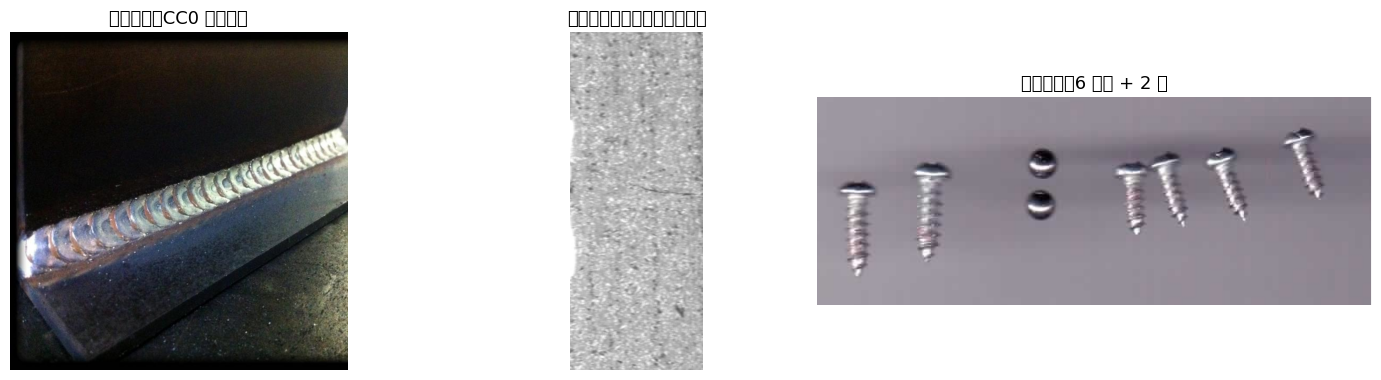

In [3]:
lab.show_images([lab.load_case("weld_good"), lab.load_case("kolektor_defect_0"),
                 lab.load_case("parts_separated")],
                ["真实焊缝：CC0 来源语义", "真实工业表面：原始缺陷掩膜", "真实零件：6 螺钉 + 2 球"], cols=3)

## 3. 标注不是算法预测

下面黄色框来自公开焊缝数据的原始 YOLO 标注；本课没有训练或运行检测器。显示原标注只是为了理解框坐标。YOLO 的中心坐标和宽高以整图归一化；显示时要乘原图宽高，不能固定乘 640。

[{'category_id': 1,
  'label': 'Good Weld',
  'bbox': [39, 294, 364, 172],
  'status': 'REVIEW',
  'source': 'upstream_annotation'},
 {'category_id': 1,
  'label': 'Good Weld',
  'bbox': [409, 207, 230, 112],
  'status': 'REVIEW',
  'source': 'upstream_annotation'}]

/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 25293 (\N{CJK UNIFIED IDEOGRAPH-62CD}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 28216 (\N{CJK UNIFIED IDEOGRAPH-6E38}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/CV/cv-beginner-course/courses/industrial-vision-lab/lab_utils.py:86: UserWarning: Glyph 27880 (\N{CJK UNIFIED IDEOGRAPH-6CE8}) missing from font(s) DejaVu Sans.
  fig.tight_layout()
/ds1/workspace/

/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 25293 (\N{CJK UNIFIED IDEOGRAPH-62CD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 19978 (\N{CJK UNIFIED IDEOGRAPH-4E0A}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 28216 (\N{CJK UNIFIED IDEOGRAPH-6E38}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/python3.12/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 26631 (\N{CJK UNIFIED IDEOGRAPH-6807}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/ds1/workspace/CV/cv-beginner-course/.venv/lib/p

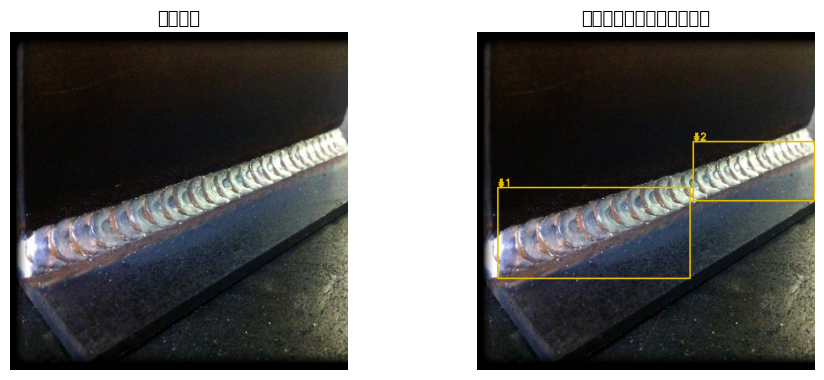

In [4]:
image = lab.load_case("weld_good")
labels = lab.pixel_yolo_labels("weld_good", image)
display(labels)
lab.show_images([image, lab.draw_boxes(image, labels)], ["原始实拍", "上游标注叠框（不是推理）"], cols=2)

## 动手检查

把 `weld_good` 改成 `weld_crack`，比较标注。再看图片的 `shape`：顺序是高、宽、通道。OpenCV 读入彩色图片用 BGR 顺序，本课显示函数会转换成 RGB。若发现“数量正确但框错了”，也不能算定位完成。

产线迁移顺序：拍清楚 → 定位汇流排 → 找镍片 → 对齐焊格 → 判七格外观 → 保存证据。强度与内部熔合不能仅凭二维外观保证。

## 来源与练习边界

公开焊缝：sukmaadhiwijaya / rikkarth，固定提交 `8b80d1afe88c0b946500a498cbdb9d7a1eda5533`，数据卡声明 CC0-1.0；工业表面：Kolektor Group / ViCoS，CC BY-NC-SA 4.0；分散零件：Tung1213，CC BY-SA 3.0；重叠零件：Technologyfelix，CC BY-SA 4.0。相关照片和派生图保留原许可及署名。

完整来源、原许可页、下载路径及 SHA256 见 [DATA_SOURCES.md](../DATA_SOURCES.md) 和 [source_manifest.json](../sources/source_manifest.json)。本课是非商业教学。灰度、二值、叠框及扰动均为原照片的派生图，七格合成图另有醒目标记。它们不等于新增独立验收数据，也不证明电池焊接准确率或机械强度。